# Modelos predictores no lineales: árbol y bosque

En este notebook copmparamos el desempeño predictivo del árbol de regresión y el bosque aleatorio. Usaremos los datosde salario sy empleo para Barranquilla. En ejercicios pasados observamos que MCO sobreajusta cuando la dimensionalidad crece, y mostramos cómo Lasso mejora la predicción en estas circunstancias. 

In [1]:
suppressWarnings(
pacman::p_load(xtable, dplyr, caret, rpart, RColorBrewer, rpart.plot, randomForest)
)

Installing package into ‘C:/Users/andre/AppData/Local/R/win-library/4.5’
(as ‘lib’ is unspecified)
also installing the dependencies ‘ModelMetrics’, ‘pROC’, ‘reshape2’



trying URL 'https://cran.rstudio.com/bin/windows/contrib/4.5/ModelMetrics_1.2.2.2.zip'
trying URL 'https://cran.rstudio.com/bin/windows/contrib/4.5/pROC_1.19.1.zip'
trying URL 'https://cran.rstudio.com/bin/windows/contrib/4.5/reshape2_1.4.5.zip'
trying URL 'https://cran.rstudio.com/bin/windows/contrib/4.5/caret_7.0-1.zip'


package ‘ModelMetrics’ successfully unpacked and MD5 sums checked
package ‘pROC’ successfully unpacked and MD5 sums checked
package ‘reshape2’ successfully unpacked and MD5 sums checked
package ‘caret’ successfully unpacked and MD5 sums checked

The downloaded binary packages are in
	C:\Users\andre\AppData\Local\Temp\RtmpwZsLHe\downloaded_packages

caret installed
Installing package into ‘C:/Users/andre/AppData/Local/R/win-library/4.5’
(as ‘lib’ is unspecified)


trying URL 'https://cran.rstudio.com/bin/windows/contrib/4.5/rpart.plot_3.1.5.zip'
Content type 'application/zip' length 1018785 bytes (994 KB)
downloaded 994 KB



package ‘rpart.plot’ successfully unpacked and MD5 sums checked

The downloaded binary packages are in
	C:\Users\andre\AppData\Local\Temp\RtmpwZsLHe\downloaded_packages

rpart.plot installed
Installing package into ‘C:/Users/andre/AppData/Local/R/win-library/4.5’
(as ‘lib’ is unspecified)


trying URL 'https://cran.rstudio.com/bin/windows/contrib/4.5/randomForest_4.7-1.2.zip'
Content type 'application/zip' length 226227 bytes (220 KB)
downloaded 220 KB



package ‘randomForest’ successfully unpacked and MD5 sums checked

The downloaded binary packages are in
	C:\Users\andre\AppData\Local\Temp\RtmpwZsLHe\downloaded_packages

randomForest installed


In [24]:
file<-"https://raw.githubusercontent.com/andvarga-eco/econometrics_ml/refs/heads/main/data/geih_24_baq.csv"
data<-read.csv(file)

In [26]:
data<-data|>filter(P6040 %in% 25:64)|>filter(P3042!=99)
data<-na.omit(data)
data<-data|>filter(P6800<=60)|>mutate(w=INGLABO/(P6800*4),lw=log(w),
                                      edad2=P6040^2, edad3=P6040^3, edad4=P6040^4)
data<-data|>mutate(P3271=factor(P3271), P3042=factor(P3042),
RAMA2D_R4=forcats::fct_lump_n(factor(RAMA2D_R4),n=40,other_level="Otras"))

In [27]:
set.seed(1234)
training <- sample(nrow(data), nrow(data) * (3 / 4), replace = FALSE)
data_train <- data[training, ]
data_test <- data[-training, ]

## Árbol de regresión


Regression tree:
rpart(formula = basic, data = data_train, minbucket = 5, cp = 0.01)

Variables actually used in tree construction:
[1] P3042     RAMA2D_R4

Root node error: 1176.4/3122 = 0.37682

n= 3122 

        CP nsplit rel error  xerror     xstd
1 0.331091      0   1.00000 1.00133 0.037514
2 0.082192      1   0.66891 0.66990 0.027553
3 0.015320      2   0.58672 0.58800 0.025360
4 0.014516      3   0.57140 0.59118 0.025161
5 0.010325      4   0.55688 0.57934 0.024873
6 0.010000      5   0.54656 0.57844 0.024845

Regression tree:
rpart(formula = basic, data = data_train, minbucket = 5, cp = 0.01)

Variables actually used in tree construction:
[1] P3042     RAMA2D_R4

Root node error: 1176.4/3122 = 0.37682

n= 3122 

        CP nsplit rel error  xerror     xstd
1 0.331091      0   1.00000 1.00133 0.037514
2 0.082192      1   0.66891 0.66990 0.027553
3 0.015320      2   0.58672 0.58800 0.025360
4 0.014516      3   0.57140 0.59118 0.025161
5 0.010325      4   0.55688 0.57934 0.024873

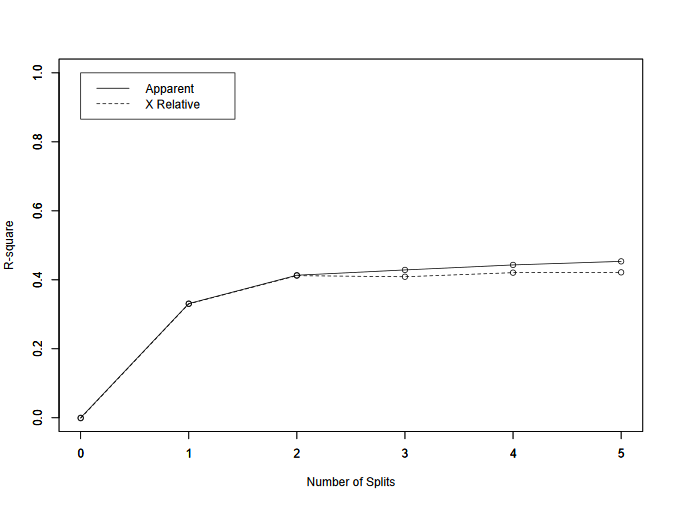

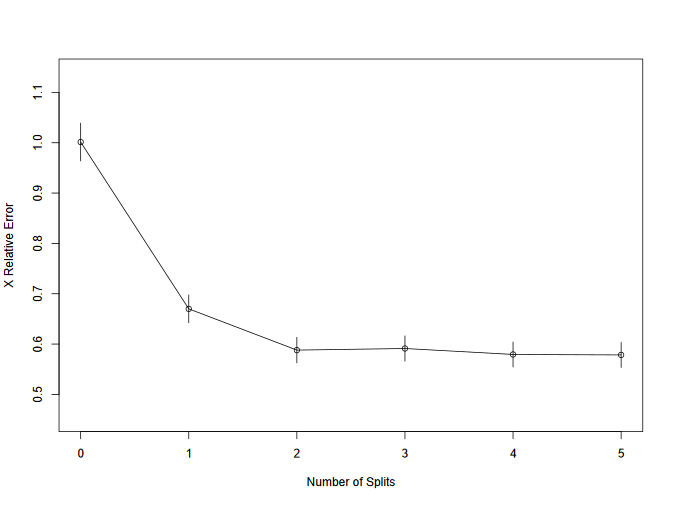

In [28]:
basic<-lw~(P3271+P6040+P3042+RAMA2D_R4)
tree.fit.basic<-rpart(basic,data=data_train,minbucket=5,cp=0.01)
printcp(tree.fit.basic)
rsq.rpart((tree.fit.basic))

In [29]:
bestcp <- tree.fit.basic$cptable[which.min(tree.fit.basic$cptable[, "xerror"]), "CP"]
bestcp

[1] 0.01


Regression tree:
rpart(formula = basic, data = data_train, minbucket = 5, cp = 0.01)

Variables actually used in tree construction:
[1] P3042     RAMA2D_R4

Root node error: 1176.4/3122 = 0.37682

n= 3122 

        CP nsplit rel error  xerror     xstd
1 0.331091      0   1.00000 1.00133 0.037514
2 0.082192      1   0.66891 0.66990 0.027553
3 0.015320      2   0.58672 0.58800 0.025360
4 0.014516      3   0.57140 0.59118 0.025161
5 0.010325      4   0.55688 0.57934 0.024873
6 0.010000      5   0.54656 0.57844 0.024845


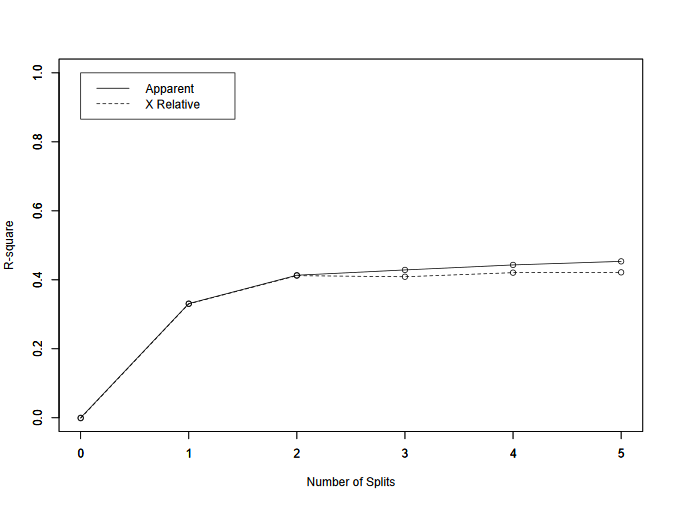

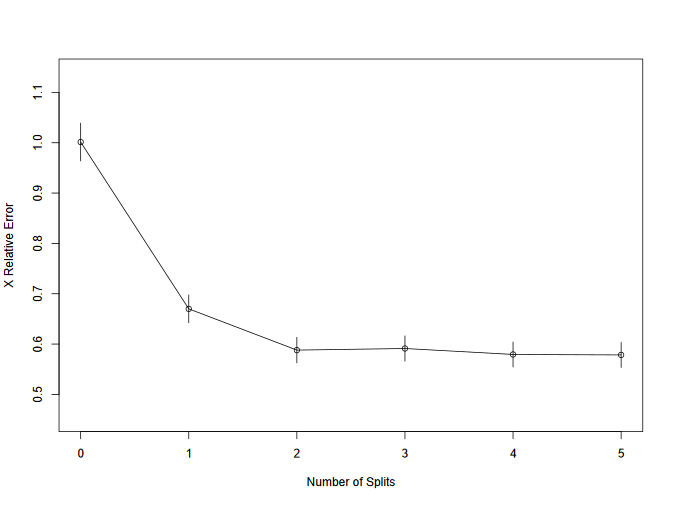

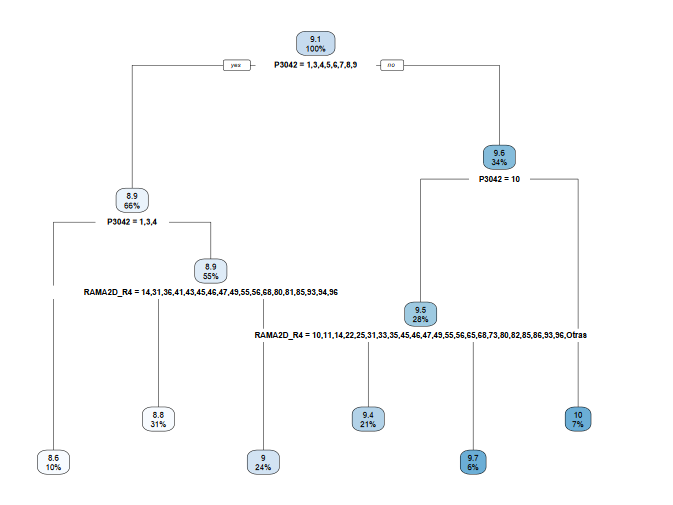

In [30]:
fit_prunedtree <- prune(tree.fit.basic, cp = bestcp)
rsq.rpart(fit_prunedtree)
rpart.plot(fit_prunedtree)

In [31]:
y_test<-data_test$lw
yhat_pt <- predict(fit_prunedtree, newdata = data_test)
mse_pt <- summary(lm((y_test - yhat_pt)^2 ~ 1))$coef[1:2]
r2_pt <- 1 - mse_pt[1] / var(y_test)
cat("R2:",round(r2_pt,2),
" | MSE:",round(mse_pt[1],2), "\n")

R2: 0.41  | MSE: 0.21 


## Bagging

In [34]:
p <- length(all.vars(basic)) - 1

In [35]:

fit_bagg <- randomForest(basic, ntree = 2000, nodesize = 20,mtry=p, data = data_train)
fit_bagg
yhat_bagg<-predict(fit_bagg,newdata = data_test)
mse_bagg <- summary(lm((y_test - yhat_bagg)^2 ~ 1))$coef[1:2]
r2_bagg<- 1 - mse_bagg[1] / var(y_test)
cat("R2:",round(r2_bagg,2),
" | MSE:",round(mse_bagg[1],2), "\n")

R2: 0.43  | MSE: 0.2 


## Ranfom forest sin Bagging

In [36]:
fit_rf <- randomForest(basic,ntree = 2000, nodesize = 20, data = data_train)
fit_rf
yhat_rf<-predict(fit_rf,newdata = data_test)
mse_rf<- summary(lm((y_test - yhat_rf)^2 ~ 1))$coef[1:2]
r2_rf<- 1 - mse_rf[1] / var(y_test)
cat("R2:",round(r2_rf,2),
" | MSE:",round(mse_rf[1],2), "\n")

R2: 0.42  | MSE: 0.2 
